# Query-aligned teacher–student classification

A two-qubit data re-uploading circuit with a fixed nonlocal query encoding
$Q_\ell(\boldsymbol f)$ is used as a teacher: its score $v_T(\boldsymbol x)$
defines binary labels $y=\mathbb 1[v_T(\boldsymbol x)>0]$. Students with the
same architecture are trained with the **correct query** $\boldsymbol f^\star$,
a **wrong query** $2\boldsymbol f^\star$, or **no query** $\boldsymbol f=\boldsymbol 0$
(for which the score is separable across $x_0|x_1$). The experiment has two
deliberately separate stages:

1. **Score realizability (Stage A).** On a dense grid, fit the continuous
   teacher score. This verifies that the correct-query model contains the
   teacher and measures the best-found approximation errors of the wrong-query
   and no-query models. It is a structural diagnostic, not a learning curve.
2. **Classification (Stage B).** Train each student on hard labels with binary
   cross-entropy and report held-out balanced accuracy as a function of the
   number of training examples $N_{\rm train}$.

**Paper figure.** The two-panel figure (a: learning curves, b: realizability
diagnostic) is the teacher–student classification figure of the paper. The
decision-boundary figure at the end (one teacher, one fold) is supplementary.

**Outputs.**
- `../results/teacher_student/teacher_student_paper.json` — configuration,
  teachers, Stage A and Stage B results (cached).
- `../figures/fig_05_teacher_student_classification.{pdf,png}` — main figure.
- `../figures/fig_05_teacher_student_classification_decision_boundary.{pdf,png}`
  — supplementary decision-boundary figure.

**Rerunning.** If the cached JSON for the selected profile exists and its
configuration matches, Stages A and B are loaded from it and only the cheap
teacher selection and the three students of the decision-boundary figure are
recomputed (about a minute). To recompute everything, delete
`../results/teacher_student/teacher_student_paper.json` (roughly 35 min on a
laptop CPU, almost all of it Stage B). Setting `PROFILE = "smoke"` runs a small
pipeline check in a few minutes; its outputs carry a `_smoke` suffix and must
not be used for reported numbers. Figure text is typeset with LaTeX when an
installation is available (falls back to mathtext otherwise; set `USE_TEX=0`
to force the fallback).

## Setup

In [1]:
import json
import os
import shutil
import subprocess
import time
from dataclasses import dataclass
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.optimize import least_squares, minimize

jax.config.update("jax_enable_x64", True)


def latex_is_usable():
    """True if this installation can serve matplotlib's usetex."""
    if shutil.which("latex") is None or shutil.which("dvipng") is None:
        return False
    try:
        completed = subprocess.run(
            ["kpsewhich", "latex.ltx"],
            capture_output=True,
            timeout=30,
            check=False,
        )
    except (OSError, subprocess.SubprocessError):
        return False
    return completed.returncode == 0 and bool(completed.stdout.strip())


# Honour USE_TEX=1 (default) only if LaTeX is usable; otherwise fall back to
# mathtext with the Computer Modern font set.
USE_TEX_REQUESTED = os.environ.get("USE_TEX", "1") == "1"
USE_TEX = USE_TEX_REQUESTED and latex_is_usable()
DASH = "--" if USE_TEX else "–"
if USE_TEX_REQUESTED and not USE_TEX:
    print("usetex requested but not available; figures use mathtext instead.")


def configure_matplotlib():
    """Compact single-column paper styling."""
    mpl.rcParams.update(
        {
            "text.usetex": USE_TEX,
            "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}",
            "font.family": "serif",
            "font.serif": ["Computer Modern Roman", "DejaVu Serif"],
            "mathtext.fontset": "cm",
            "font.size": 8,
            "axes.labelsize": 8,
            "axes.titlesize": 8,
            "axes.linewidth": 0.6,
            "axes.spines.top": True,
            "axes.spines.right": True,
            "xtick.labelsize": 7.5,
            "ytick.labelsize": 7.5,
            "xtick.major.width": 0.5,
            "ytick.major.width": 0.5,
            "xtick.minor.width": 0.4,
            "ytick.minor.width": 0.4,
            "xtick.direction": "in",
            "ytick.direction": "in",
            "legend.fontsize": 6.9,
            "legend.handlelength": 2.1,
            "legend.columnspacing": 1.2,
            "lines.linewidth": 1.3,
            "savefig.bbox": None,
        }
    )


configure_matplotlib()

# Colour and dash pattern both carry the arm identity, so the panels stay
# readable in greyscale and for colour-vision deficiency.
COLORS = {"correct": "#C0392B", "wrong": "#8E44AD", "none": "#7F8C8D"}
STYLE = {"correct": "-", "wrong": (0, (4, 2)), "none": (0, (5, 1.5, 1, 1.5))}
MARKER = {"correct": "o", "wrong": "s", "none": "^"}
LABELS = {
    "correct": r"correct query $\boldsymbol{f}^\star$",
    "wrong": r"wrong query $2\boldsymbol{f}^\star$",
    "none": r"no query $\boldsymbol{0}$",
}
BAND_ALPHA = {"correct": 0.14, "wrong": 0.13, "none": 0.12}

## Configuration

`BLOCK = "ry"` is the deliberately minimal controlled model: each trainable
single-qubit factor is an $R_Y$ rotation, giving eight trainable parameters at
$n_q=2$ (it is not a full-SU(2) ansatz; `"yzy"` would restore arbitrary
single-qubit SU(2) factors). The `paper` profile produces the reported results;
`smoke` is a quick end-to-end check.

In [2]:
N_QUBITS = 2
N_LAYERS = 2
BLOCK = "ry"
F_STAR_PAIR = np.array([np.pi / 4, np.pi / 3])
WRONG_SCALE = 2.0
BETA = 5.0

PROFILE = "paper"
PROFILES = {
    "smoke": dict(
        n_teachers=2,
        n_folds=5,
        n_grid=[8, 16, 32],
        n_test=1500,
        n_probe=5000,
        n_restarts=4,
        adam_steps=300,
        adam_lr=0.035,
        polish_top=1,
        polish_maxiter=120,
        score_restarts=4,
        score_max_nfev=250,
        bootstrap_samples=500,
    ),
    "paper": dict(
        n_teachers=10,
        n_folds=8,
        n_grid=[8, 16, 32, 64, 128, 256],
        n_test=10000,
        n_probe=20000,
        n_restarts=16,
        adam_steps=2000,
        adam_lr=0.03,
        polish_top=3,
        polish_maxiter=500,
        score_restarts=32,
        score_max_nfev=1000,
        bootstrap_samples=5000,
    ),
}
if PROFILE not in PROFILES:
    raise ValueError(f"unknown PROFILE={PROFILE!r}")
P = PROFILES[PROFILE]

TEACHER_SEEDS = list(range(P["n_teachers"]))
BALANCE = (0.4, 0.6)
MIN_NONSEP = 0.2
MAX_TEACHER_DRAWS = 4000
WARM_START_ACROSS_N = False
BASE_SEED = 1729

RESULTS_DIR = Path("../results/teacher_student")
FIGURES_DIR = Path("../figures")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULT_PATH = RESULTS_DIR / f"teacher_student_{PROFILE}.json"
FIGURE_STEM = "fig_05_teacher_student_classification" + (
    "" if PROFILE == "paper" else f"_{PROFILE}"
)

print(
    f"profile={PROFILE} | block={BLOCK} | teachers={P['n_teachers']} | "
    f"folds={P['n_folds']} | n={P['n_grid']}"
)
if PROFILE != "paper":
    print("Smoke profile: pipeline check only, not for reported numbers.")

profile=paper | block=ry | teachers=10 | folds=8 | n=[8, 16, 32, 64, 128, 256]


## Circuit and query family

For two qubits the circuit is

$$
U(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)
=
\prod_{\ell=1}^{2}
V_\ell(\boldsymbol\theta)\,
Q_\ell(\boldsymbol f)\,
W_\ell(\boldsymbol\theta)\,
E_x(\boldsymbol x),
$$

acting on $|{+}\rangle^{\otimes 2}$, with $E_x(\boldsymbol x)=R_{Z_0}(x_0)R_{Z_1}(x_1)$,
query scales $(s_1,s_2)=(1,2)$, and

$$
Q_\ell(\boldsymbol f)
=
R_{Z_0Y_1}(s_\ell f_1)\,
R_{Y_0Z_1}(s_\ell f_0).
$$

The two query generators commute. The score is the parity expectation
$v(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)=\langle Z_0Z_1\rangle\in[-1,1]$.
The trainable blocks $W_\ell$, $V_\ell$ are products of single-qubit rotations
($R_Y$ for `BLOCK = "ry"`). The correct and wrong arms use the same nonlocal
query encoding with different fixed values, $\boldsymbol f^\star=(\pi/4,\pi/3)$
and $2\boldsymbol f^\star$. The no-query arm sets $\boldsymbol f=\boldsymbol 0$,
for which the circuit factorizes and the score is separable across $x_0|x_1$.

Nonseparability of a score is measured on its Fourier-coefficient matrix
$C$ (modes $-2,\dots,2$ per input) as $1-\sigma_1^2/\sum_k\sigma_k^2$, which is
zero exactly for separable scores. The cell ends with a few consistency checks.

In [3]:
_I = np.eye(2, dtype=complex)
_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
_Z = np.diag([1, -1]).astype(complex)


def rng_from(*parts):
    return np.random.default_rng(
        np.random.SeedSequence([int(part) for part in parts])
    )


@dataclass(frozen=True)
class Cfg:
    n_qubits: int = 2
    n_layers: int = 2
    block: str = "ry"

    def __post_init__(self):
        if self.n_qubits % 2:
            raise ValueError("the YZ/ZY dimer construction needs an even n_qubits")
        if self.block not in {"ry", "yzy"}:
            raise ValueError("block must be 'ry' or 'yzy'")

    @property
    def n_dimers(self):
        return self.n_qubits // 2

    @property
    def dimers(self):
        return [(2 * d, 2 * d + 1) for d in range(self.n_dimers)]

    @property
    def scales(self):
        return np.arange(1, self.n_layers + 1, dtype=float)

    @property
    def n_params(self):
        per_single_qubit = 1 if self.block == "ry" else 3
        return self.n_layers * 2 * self.n_qubits * per_single_qubit

    def expand(self, free_parameters):
        free_parameters = jnp.asarray(free_parameters).ravel()
        shape = (self.n_layers, 2, self.n_qubits)
        if self.block == "yzy":
            return free_parameters.reshape(*shape, 3)
        return jnp.zeros((*shape, 3)).at[:, :, :, 1].set(
            free_parameters.reshape(*shape)
        )

    def free(self, full_parameters):
        full = np.asarray(full_parameters).reshape(
            self.n_layers, 2, self.n_qubits, 3
        )
        if self.block == "yzy":
            return full.ravel()
        return full[:, :, :, 1].ravel()


CFG = Cfg(N_QUBITS, N_LAYERS, BLOCK)


def make_f_star(n_qubits):
    return np.tile(F_STAR_PAIR, n_qubits // 2).astype(float)


F_STAR = make_f_star(CFG.n_qubits)
ARMS = {
    "correct": F_STAR.copy(),
    "wrong": WRONG_SCALE * F_STAR,
    "none": np.zeros_like(F_STAR),
}


def kron_all_numpy(matrices):
    out = np.array([[1.0]], dtype=complex)
    for matrix in matrices:
        out = np.kron(out, matrix)
    return out


def query_generators(n_qubits):
    generators = []
    for i, j in [(2 * d, 2 * d + 1) for d in range(n_qubits // 2)]:
        for left, right in ((_Y, _Z), (_Z, _Y)):
            matrices = [_I] * n_qubits
            matrices[i], matrices[j] = left, right
            generators.append(kron_all_numpy(matrices))
    return generators


def maximum_generator_commutator(n_qubits):
    generators = query_generators(n_qubits)
    return max(
        float(np.max(np.abs(a @ b - b @ a)))
        for i, a in enumerate(generators)
        for b in generators[i + 1 :]
    )


def basis_signs(n_qubits):
    indices = np.arange(2**n_qubits)
    bits = (
        indices[:, None]
        >> np.arange(n_qubits - 1, -1, -1)[None, :]
    ) & 1
    return 1.0 - 2.0 * bits


def _su2_jax(parameters):
    a, b, c = parameters
    rz = lambda angle: jnp.diag(
        jnp.array(
            [jnp.exp(-0.5j * angle), jnp.exp(0.5j * angle)],
            dtype=jnp.complex128,
        )
    )
    cosine = jnp.cos(b / 2).astype(jnp.complex128)
    sine = jnp.sin(b / 2).astype(jnp.complex128)
    ry = jnp.array([[cosine, -sine], [sine, cosine]], dtype=jnp.complex128)
    return rz(c) @ ry @ rz(a)


def _kron_jax(matrices):
    out = jnp.eye(1, dtype=jnp.complex128)
    for matrix in matrices:
        out = jnp.kron(out, matrix)
    return out


def _query_jax(f, scale, cfg):
    yz = jnp.asarray(np.kron(_Y, _Z))
    zy = jnp.asarray(np.kron(_Z, _Y))
    identity = jnp.eye(4, dtype=jnp.complex128)

    def rotation(angle, generator):
        return (
            jnp.cos(angle / 2).astype(jnp.complex128) * identity
            - 1j * jnp.sin(angle / 2).astype(jnp.complex128) * generator
        )

    dimer_gates = []
    for dimer in range(cfg.n_dimers):
        f0, f1 = f[2 * dimer], f[2 * dimer + 1]
        dimer_gates.append(
            rotation(scale * f1, zy) @ rotation(scale * f0, yz)
        )
    return _kron_jax(dimer_gates)


def forward(full_parameters, x, f, cfg=CFG):
    dimension = 2**cfg.n_qubits
    signs = basis_signs(cfg.n_qubits)
    parity = jnp.asarray(np.prod(signs, axis=1))
    initial = jnp.full(
        (dimension,), 1.0 / np.sqrt(dimension), dtype=jnp.complex128
    )

    theta = jnp.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )
    x = jnp.atleast_2d(jnp.asarray(x))
    f = jnp.asarray(f)
    data_phase = jnp.exp(-0.5j * (x @ jnp.asarray(signs).T))

    state = jnp.broadcast_to(initial, (x.shape[0], dimension))
    for layer in range(cfg.n_layers):
        state = state * data_phase
        w_layer = _kron_jax(
            [_su2_jax(theta[layer, 0, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ w_layer.T
        state = state @ _query_jax(f, cfg.scales[layer], cfg).T
        v_layer = _kron_jax(
            [_su2_jax(theta[layer, 1, q]) for q in range(cfg.n_qubits)]
        )
        state = state @ v_layer.T

    return jnp.real(jnp.sum(jnp.abs(state) ** 2 * parity, axis=1))


def sample_free_prior(rng, cfg=CFG):
    if cfg.block == "ry":
        return rng.uniform(-np.pi, np.pi, cfg.n_params)

    shape = (cfg.n_layers, 2, cfg.n_qubits)
    a = rng.uniform(0.0, 2 * np.pi, shape)
    c = rng.uniform(0.0, 2 * np.pi, shape)
    b = np.arccos(1.0 - 2.0 * rng.uniform(0.0, 1.0, shape))
    return np.stack([a, b, c], axis=-1).ravel()


def fourier_matrix(full_parameters, f, cfg=CFG, dimer=0):
    modes_per_axis = 2 * cfg.n_layers + 1
    sub_cfg = Cfg(2, cfg.n_layers, cfg.block)
    i, j = cfg.dimers[dimer]
    theta = np.asarray(full_parameters).reshape(
        cfg.n_layers, 2, cfg.n_qubits, 3
    )[:, :, [i, j], :]
    f_sub = np.asarray(f)[[i, j]]
    grid = 2 * np.pi * np.arange(modes_per_axis) / modes_per_axis
    x0, x1 = np.meshgrid(grid, grid, indexing="ij")
    points = np.stack([x0.ravel(), x1.ravel()], axis=1)
    values = np.asarray(forward(theta, points, f_sub, sub_cfg)).reshape(
        modes_per_axis, modes_per_axis
    )
    return np.fft.fftshift(
        np.fft.fft2(values) / modes_per_axis**2
    )


def coefficient_nonseparability(full_parameters, f, cfg=CFG):
    result = {}
    for dimer in range(cfg.n_dimers):
        singular_values = np.linalg.svd(
            fourier_matrix(full_parameters, f, cfg, dimer),
            compute_uv=False,
        )
        result[f"dimer{dimer}"] = float(
            1.0
            - singular_values[0] ** 2
            / np.sum(singular_values**2)
        )
    result["min"] = min(
        result[f"dimer{d}"] for d in range(cfg.n_dimers)
    )
    return result


def operator_nonseparable_weight(gate):
    reshuffled = (
        np.asarray(gate)
        .reshape(2, 2, 2, 2)
        .transpose(0, 2, 1, 3)
        .reshape(4, 4)
    )
    singular_values = np.linalg.svd(reshuffled, compute_uv=False)
    weights = singular_values**2
    return float(1.0 - weights[0] / np.sum(weights))


assert maximum_generator_commutator(CFG.n_qubits) < 1e-12
unit_rng = rng_from(BASE_SEED, 1)
unit_w = sample_free_prior(unit_rng, CFG)
unit_theta = np.asarray(CFG.expand(unit_w))
unit_x = unit_rng.uniform(0, 2 * np.pi, (64, CFG.n_qubits))
unit_values = np.asarray(forward(unit_theta, unit_x, F_STAR, CFG))
assert np.max(np.abs(unit_values)) <= 1.0 + 1e-10
assert coefficient_nonseparability(
    unit_theta, np.zeros_like(F_STAR), CFG
)["min"] < 1e-10
generic_query = np.asarray(_query_jax(F_STAR, 1.0, CFG))
if CFG.n_qubits == 2:
    assert operator_nonseparable_weight(generic_query) > 1e-3

print(
    f"circuit checks passed | n_params={CFG.n_params} | "
    f"f*={np.round(F_STAR, 4)} | wrong={np.round(ARMS['wrong'], 4)}"
)

circuit checks passed | n_params=8 | f*=[0.7854 1.0472] | wrong=[1.5708 2.0944]


## Teacher ensemble

Each teacher is sampled from the same free-parameter prior used for student
initialization. We retain the first draw satisfying two predeclared conditions:
approximately balanced labels (positive fraction in $(0.4, 0.6)$) and a
nonseparable coefficient matrix (nonseparability $>0.2$). This conditioning is
intentional and is recorded for every teacher; it constructs a controlled task
in which the no-query separable endpoint is genuinely misspecified.

Teacher selection uses an independent probe set; no reported training or test
example participates in it. Selection is cheap and is always recomputed.

In [4]:
def select_teacher(
    cfg,
    f_star,
    teacher_seed,
    *,
    n_probe,
    balance=BALANCE,
    min_nonsep=MIN_NONSEP,
    max_draws=MAX_TEACHER_DRAWS,
):
    probe_rng = rng_from(BASE_SEED, 100, teacher_seed)
    parameter_rng = rng_from(BASE_SEED, 101, teacher_seed)
    x_probe = probe_rng.uniform(
        0, 2 * np.pi, (n_probe, cfg.n_qubits)
    )

    for draw in range(1, max_draws + 1):
        free_parameters = sample_free_prior(parameter_rng, cfg)
        full_parameters = np.asarray(cfg.expand(free_parameters))
        score = np.asarray(forward(full_parameters, x_probe, f_star, cfg))
        positive_fraction = float(np.mean(score > 0))
        if not (balance[0] < positive_fraction < balance[1]):
            continue

        nonseparability = coefficient_nonseparability(
            full_parameters, f_star, cfg
        )
        if nonseparability["min"] <= min_nonsep:
            continue

        return {
            "teacher": int(teacher_seed),
            "draws": int(draw),
            "free_parameters": np.asarray(free_parameters),
            "full_parameters": full_parameters,
            "balance": positive_fraction,
            "nonseparability": nonseparability,
            "boundary_mass_005": float(np.mean(np.abs(score) < 0.05)),
        }

    raise RuntimeError(
        f"teacher {teacher_seed} did not pass the predeclared criteria "
        f"in {max_draws} draws"
    )


t0 = time.time()
TEACHERS = [
    select_teacher(
        CFG,
        F_STAR,
        seed,
        n_probe=P["n_probe"],
    )
    for seed in TEACHER_SEEDS
]

teacher_table = pd.DataFrame(
    [
        {
            "teacher": t["teacher"],
            "draws": t["draws"],
            "balance": t["balance"],
            "nonseparability": t["nonseparability"]["min"],
            "boundary_mass_005": t["boundary_mass_005"],
        }
        for t in TEACHERS
    ]
)
print(teacher_table.to_string(index=False))
print(f"selected {len(TEACHERS)} teachers in {time.time() - t0:.1f}s")

 teacher  draws  balance  nonseparability  boundary_mass_005
       0      1  0.44610         0.252383            0.08915
       1      5  0.43815         0.595118            0.11495
       2      2  0.51450         0.271047            0.04985
       3      1  0.53520         0.467105            0.09780
       4      5  0.52015         0.521541            0.08865
       5      4  0.43140         0.509167            0.06320
       6      3  0.44020         0.522358            0.10470
       7      3  0.49605         0.322941            0.06630
       8      4  0.42420         0.545583            0.09600
       9      1  0.48375         0.596251            0.06025
selected 10 teachers in 0.6s


## Results cache

Stages A and B are loaded from `RESULT_PATH` when that file exists and was
produced with the identical configuration and teachers; otherwise they are
computed below and the file is written.

In [5]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    return value


CONFIG = json_safe(
    {
        "profile": PROFILE,
        "n_qubits": CFG.n_qubits,
        "n_layers": CFG.n_layers,
        "block": CFG.block,
        "n_params": CFG.n_params,
        "f_star": F_STAR,
        "arms": ARMS,
        "beta": BETA,
        "balance_filter": BALANCE,
        "minimum_nonseparability": MIN_NONSEP,
        "warm_start_across_n": WARM_START_ACROSS_N,
        **P,
    }
)
TEACHER_RECORDS = json_safe(
    [
        {
            "teacher": teacher["teacher"],
            "draws": teacher["draws"],
            "free_parameters": teacher["free_parameters"],
            "balance": teacher["balance"],
            "nonseparability": teacher["nonseparability"],
            "boundary_mass_005": teacher["boundary_mass_005"],
        }
        for teacher in TEACHERS
    ]
)

CACHE = None
if RESULT_PATH.exists():
    cached = json.loads(RESULT_PATH.read_text())
    if cached["config"] != CONFIG:
        raise ValueError(
            f"{RESULT_PATH} was produced with a different configuration; "
            "delete it to recompute."
        )
    for new, old in zip(TEACHER_RECORDS, cached["teachers"], strict=True):
        assert new["draws"] == old["draws"]
        assert np.allclose(new["free_parameters"], old["free_parameters"])
    CACHE = cached
    print(f"loaded cached results from {RESULT_PATH}")
else:
    print(f"no cached results at {RESULT_PATH}; Stages A and B will run")

loaded cached results from ../results/teacher_student/teacher_student_paper.json


## Stage A — score-realizability diagnostic

This stage uses the continuous teacher score on a dense, independently
constructed $15\times15$ grid. It is not a classification experiment and does
not use the reported test sets.

For every teacher and arm, a fixed number of trust-region least-squares fits is
performed from paired initial parameters. The known teacher parameters are
included as one common start for all arms. Thus the correct arm provides a
numerical implementation check, while the other values are explicitly
best-found approximation errors rather than proofs of nonrepresentability.
The no-query obstruction is independently certified by separability.

In [6]:
def score_fit(
    cfg,
    f,
    x,
    target,
    starts,
    *,
    max_nfev,
):
    x_jax = jnp.asarray(x)
    f_jax = jnp.asarray(f)
    target_jax = jnp.asarray(target)

    prediction = lambda w: forward(cfg.expand(w), x_jax, f_jax, cfg)
    residual = jax.jit(lambda w: prediction(w) - target_jax)
    jacobian = jax.jit(jax.jacfwd(prediction))

    best_loss = np.inf
    best_parameters = None
    for start in starts:
        result = least_squares(
            lambda w: np.asarray(residual(jnp.asarray(w))),
            np.asarray(start),
            jac=lambda w: np.asarray(jacobian(jnp.asarray(w))),
            method="trf",
            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12,
            max_nfev=max_nfev,
        )
        loss = float(np.mean(result.fun**2))
        if loss < best_loss:
            best_loss = loss
            best_parameters = np.asarray(result.x)

    prediction_best = np.asarray(
        forward(cfg.expand(best_parameters), x, f, cfg)
    )
    relative_mse = float(
        np.mean((prediction_best - target) ** 2)
        / np.mean(np.asarray(target) ** 2)
    )
    return {
        "mse": best_loss,
        "relative_mse": relative_mse,
    }


def diagnostic_grid(n_qubits, points_per_axis=15):
    if n_qubits != 2:
        raise ValueError(
            "the dense Cartesian diagnostic grid is intentionally limited "
            "to the reported two-qubit experiment"
        )
    grid = 2 * np.pi * np.arange(points_per_axis) / points_per_axis
    x0, x1 = np.meshgrid(grid, grid, indexing="ij")
    return np.stack([x0.ravel(), x1.ravel()], axis=1)


def run_score_diagnostic(cfg, teachers, arms):
    x = diagnostic_grid(cfg.n_qubits)
    rows = []
    for teacher in teachers:
        target = np.asarray(
            forward(
                teacher["full_parameters"],
                x,
                F_STAR,
                cfg,
            )
        )
        start_rng = rng_from(BASE_SEED, 200, teacher["teacher"])
        starts = [teacher["free_parameters"].copy()]
        starts.extend(
            sample_free_prior(start_rng, cfg)
            for _ in range(P["score_restarts"] - 1)
        )
        for arm, f in arms.items():
            fit = score_fit(
                cfg,
                f,
                x,
                target,
                starts,
                max_nfev=P["score_max_nfev"],
            )
            rows.append(
                {
                    "teacher": teacher["teacher"],
                    "arm": arm,
                    **fit,
                }
            )
    return pd.DataFrame(rows)


if CACHE is not None:
    SCORE_RESULTS = pd.DataFrame(CACHE["score_results"])
else:
    t0 = time.time()
    SCORE_RESULTS = run_score_diagnostic(CFG, TEACHERS, ARMS)
    print(f"score diagnostic completed in {time.time() - t0:.1f}s")
print(
    SCORE_RESULTS.pivot_table(
        index="arm", values="relative_mse", aggfunc=["median", "min", "max"]
    )
)

              median          min          max
        relative_mse relative_mse relative_mse
arm                                           
correct     0.000000     0.000000     0.000000
none        0.544034     0.252447     0.649138
wrong       0.131560     0.031430     0.240101


## Stage B — classification learning curves

Labels are

$$
y(\boldsymbol x)=\mathbb{1}[v_T(\boldsymbol x)>0].
$$

Each student predicts

$$
p_{\boldsymbol\theta}(y=1\mid\boldsymbol x)
=\sigma\!\left[\beta\,
v(\boldsymbol x,\boldsymbol f;\boldsymbol\theta)\right],
\qquad \beta=5,
$$

and is trained by binary cross-entropy. There is no trainable classical
readout. All arms receive identical training points and paired initial
parameters. Optimization uses a fixed number of full-batch Adam steps (from
`n_restarts` prior samples in parallel, with gradient clipping and a cosine
learning-rate schedule) followed by a fixed L-BFGS polishing budget for the
best Adam starts. Model selection uses training BCE only.

Reported test sets are generated independently of teacher selection and are
never used to choose starts, budgets, hyperparameters, or accepted runs. Folds
are independent training pools; for each fold the training sets are nested
prefixes of one pool, and no warm start crosses folds or sample sizes.

In [7]:
def bce_from_logits(logits, labels):
    labels = jnp.asarray(labels)
    return jnp.mean(jax.nn.softplus(logits) - labels * logits)


def classification_loss(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    score = forward(cfg.expand(free_parameters), x, f, cfg)
    return bce_from_logits(beta * score, labels)


def make_batched_adam(
    cfg,
    *,
    beta,
    n_steps,
    learning_rate,
    gradient_clip=10.0,
):
    def loss_one(parameters, x, labels, f):
        return classification_loss(parameters, x, labels, f, cfg, beta)

    value_and_gradient = jax.vmap(
        jax.value_and_grad(loss_one),
        in_axes=(0, None, None, None),
    )

    @jax.jit
    def run(initial_parameters, x, labels, f):
        parameters = jnp.asarray(initial_parameters)
        first_moment = jnp.zeros_like(parameters)
        second_moment = jnp.zeros_like(parameters)

        def body(step, state):
            parameters, first_moment, second_moment = state
            _, gradient = value_and_gradient(parameters, x, labels, f)

            norms = jnp.linalg.norm(gradient, axis=1, keepdims=True)
            gradient = gradient * jnp.minimum(
                1.0, gradient_clip / (norms + 1e-12)
            )

            first_moment = 0.9 * first_moment + 0.1 * gradient
            second_moment = 0.999 * second_moment + 0.001 * gradient**2
            t = step + 1
            first_corrected = first_moment / (1.0 - 0.9**t)
            second_corrected = second_moment / (1.0 - 0.999**t)

            fraction = step / jnp.maximum(1, n_steps - 1)
            rate = learning_rate * (
                0.1 + 0.9 * 0.5 * (1.0 + jnp.cos(jnp.pi * fraction))
            )
            parameters = parameters - rate * first_corrected / (
                jnp.sqrt(second_corrected) + 1e-8
            )
            return parameters, first_moment, second_moment

        parameters, _, _ = jax.lax.fori_loop(
            0,
            n_steps,
            body,
            (parameters, first_moment, second_moment),
        )
        losses = jax.vmap(loss_one, in_axes=(0, None, None, None))(
            parameters, x, labels, f
        )
        return parameters, losses

    return run


ADAM_RUNNER = make_batched_adam(
    CFG,
    beta=BETA,
    n_steps=P["adam_steps"],
    learning_rate=P["adam_lr"],
)


def balanced_accuracy(labels, predictions):
    labels = np.asarray(labels, dtype=bool)
    predictions = np.asarray(predictions, dtype=bool)
    positive = labels
    negative = ~labels
    if not np.any(positive) or not np.any(negative):
        return np.nan
    sensitivity = np.mean(predictions[positive])
    specificity = np.mean(~predictions[negative])
    return float(0.5 * (sensitivity + specificity))


def evaluate_classifier(free_parameters, x, labels, f, cfg=CFG, beta=BETA):
    score = np.asarray(forward(cfg.expand(free_parameters), x, f, cfg))
    logits = beta * score
    labels = np.asarray(labels, dtype=float)
    predictions = logits > 0
    bce = float(
        np.mean(np.logaddexp(0.0, logits) - labels * logits)
    )
    return {
        "bce": bce,
        "accuracy": float(np.mean(predictions == labels)),
        "balanced_accuracy": balanced_accuracy(labels, predictions),
    }


def fit_classifier(
    cfg,
    f,
    x_train,
    y_train,
    x_test,
    y_test,
    *,
    seed,
    extra_start=None,
):
    rng = rng_from(BASE_SEED, 300, seed)
    initial = np.stack(
        [sample_free_prior(rng, cfg) for _ in range(P["n_restarts"])]
    )
    if extra_start is not None:
        initial[0] = np.asarray(extra_start)

    adam_parameters, adam_losses = ADAM_RUNNER(
        jnp.asarray(initial),
        jnp.asarray(x_train),
        jnp.asarray(y_train),
        jnp.asarray(f),
    )
    candidates = np.asarray(adam_parameters)
    losses = np.asarray(adam_losses)
    best_index = int(np.argmin(losses))
    best_parameters = candidates[best_index].copy()
    best_loss = float(losses[best_index])

    x_jax = jnp.asarray(x_train)
    y_jax = jnp.asarray(y_train)
    f_jax = jnp.asarray(f)
    objective = jax.jit(
        jax.value_and_grad(
            lambda w: classification_loss(w, x_jax, y_jax, f_jax, cfg, BETA)
        )
    )

    def value_and_jacobian(parameters):
        value, gradient = objective(jnp.asarray(parameters))
        return float(value), np.asarray(gradient, dtype=float)

    polish_indices = np.argsort(losses)[: P["polish_top"]]
    polish_successes = 0
    for index in polish_indices:
        result = minimize(
            value_and_jacobian,
            candidates[index],
            jac=True,
            method="L-BFGS-B",
            options={
                "maxiter": P["polish_maxiter"],
                "ftol": 1e-12,
                "gtol": 1e-9,
            },
        )
        if result.success:
            polish_successes += 1
        if float(result.fun) < best_loss:
            best_loss = float(result.fun)
            best_parameters = np.asarray(result.x)

    train_metrics = evaluate_classifier(
        best_parameters, x_train, y_train, f, cfg
    )
    test_metrics = evaluate_classifier(
        best_parameters, x_test, y_test, f, cfg
    )
    return {
        "free_parameters": best_parameters,
        "train_bce": train_metrics["bce"],
        "train_accuracy": train_metrics["accuracy"],
        "train_balanced_accuracy": train_metrics["balanced_accuracy"],
        "test_bce": test_metrics["bce"],
        "test_accuracy": test_metrics["accuracy"],
        "test_balanced_accuracy": test_metrics["balanced_accuracy"],
        "polish_successes": int(polish_successes),
    }

In [8]:
def run_classification_experiment(cfg, teachers, arms):
    rows = []
    n_max = max(P["n_grid"])

    for teacher in teachers:
        teacher_id = teacher["teacher"]
        theta_star = teacher["full_parameters"]

        test_rng = rng_from(BASE_SEED, 400, teacher_id)
        x_test = test_rng.uniform(
            0, 2 * np.pi, (P["n_test"], cfg.n_qubits)
        )
        teacher_test_score = np.asarray(
            forward(theta_star, x_test, F_STAR, cfg)
        )
        y_test = (teacher_test_score > 0).astype(float)

        for fold in range(P["n_folds"]):
            # Warm starts are reset for every independent fold.
            warm = {}
            pool_rng = rng_from(BASE_SEED, 401, teacher_id, fold)
            x_pool = pool_rng.uniform(
                0, 2 * np.pi, (n_max, cfg.n_qubits)
            )
            teacher_pool_score = np.asarray(
                forward(theta_star, x_pool, F_STAR, cfg)
            )
            y_pool = (teacher_pool_score > 0).astype(float)

            for n in sorted(P["n_grid"]):
                x_train = x_pool[:n]
                y_train = y_pool[:n]
                paired_seed = (
                    1_000_000 * teacher_id + 10_000 * fold + int(n)
                )

                message = []
                for arm, f in arms.items():
                    result = fit_classifier(
                        cfg,
                        f,
                        x_train,
                        y_train,
                        x_test,
                        y_test,
                        seed=paired_seed,
                        extra_start=(
                            warm.get(arm)
                            if WARM_START_ACROSS_N
                            else None
                        ),
                    )
                    if WARM_START_ACROSS_N:
                        warm[arm] = result["free_parameters"]

                    rows.append(
                        {
                            "teacher": int(teacher_id),
                            "fold": int(fold),
                            "n": int(n),
                            "arm": arm,
                            **{
                                key: value
                                for key, value in result.items()
                                if key != "free_parameters"
                            },
                        }
                    )
                    message.append(
                        f"{arm}:{result['test_balanced_accuracy']:.3f}"
                    )

                print(
                    f"teacher={teacher_id:02d} fold={fold:02d} n={n:03d} | "
                    + " ".join(message),
                    flush=True,
                )

    return pd.DataFrame(rows)


if CACHE is not None:
    CLASSIFICATION_RESULTS = pd.DataFrame(CACHE["classification_results"])
    print(f"loaded {len(CLASSIFICATION_RESULTS)} cached classification fits")
else:
    t0 = time.time()
    CLASSIFICATION_RESULTS = run_classification_experiment(
        CFG, TEACHERS, ARMS
    )
    print(f"classification experiment completed in {time.time() - t0:.1f}s")

loaded 1440 cached classification fits


## Aggregation

Folds are first averaged within each teacher. Uncertainty (95% intervals) is
then obtained by resampling teachers, preserving the pairing of all arms and
sample sizes. Consequently, the interval reflects variation across
independently generated tasks rather than treating folds from the same teacher
as independent tasks. The printed paired differences are at the largest
$N_{\rm train}$.

The smoke profile contains too few teachers for inferential uncertainty; its
interval is only a pipeline check.

In [9]:
PRIMARY_METRIC = "test_balanced_accuracy"


def teacher_level_table(results, metric):
    return (
        results.groupby(["teacher", "arm", "n"], as_index=False)[metric]
        .mean()
        .sort_values(["teacher", "arm", "n"])
    )


def paired_teacher_bootstrap(
    results,
    metric,
    *,
    n_bootstrap,
    seed=0,
):
    table = teacher_level_table(results, metric)
    teachers = np.array(sorted(table["teacher"].unique()))
    arms = list(ARMS)
    sample_sizes = sorted(table["n"].unique())

    values = np.empty((len(teachers), len(arms), len(sample_sizes)))
    for i, teacher in enumerate(teachers):
        for j, arm in enumerate(arms):
            part = table[
                (table["teacher"] == teacher) & (table["arm"] == arm)
            ].set_index("n")
            values[i, j] = part.loc[sample_sizes, metric]

    estimate = values.mean(axis=0)
    rng = rng_from(BASE_SEED, 500, seed)
    bootstrap = np.empty(
        (n_bootstrap, len(arms), len(sample_sizes))
    )
    for draw in range(n_bootstrap):
        indices = rng.integers(0, len(teachers), len(teachers))
        bootstrap[draw] = values[indices].mean(axis=0)

    lower, upper = np.quantile(bootstrap, [0.025, 0.975], axis=0)
    return {
        "teachers": teachers,
        "arms": arms,
        "n": sample_sizes,
        "estimate": estimate,
        "lower": lower,
        "upper": upper,
        "bootstrap": bootstrap,
    }


SUMMARY = paired_teacher_bootstrap(
    CLASSIFICATION_RESULTS,
    PRIMARY_METRIC,
    n_bootstrap=P["bootstrap_samples"],
)

summary_rows = []
for arm_index, arm in enumerate(SUMMARY["arms"]):
    for n_index, n in enumerate(SUMMARY["n"]):
        summary_rows.append(
            {
                "arm": arm,
                "n": n,
                "mean": SUMMARY["estimate"][arm_index, n_index],
                "lower95": SUMMARY["lower"][arm_index, n_index],
                "upper95": SUMMARY["upper"][arm_index, n_index],
            }
        )
SUMMARY_TABLE = pd.DataFrame(summary_rows)
print(SUMMARY_TABLE.to_string(index=False, float_format=lambda x: f"{x:.4f}"))


def paired_difference_at_largest_n(results, left="correct", right="wrong"):
    n = max(results["n"])
    table = teacher_level_table(results, PRIMARY_METRIC)
    pivot = (
        table[table["n"] == n]
        .pivot(index="teacher", columns="arm", values=PRIMARY_METRIC)
    )
    difference = np.asarray(pivot[left] - pivot[right])
    rng = rng_from(BASE_SEED, 501, len(right))
    bootstrap = np.array(
        [
            np.mean(
                difference[
                    rng.integers(0, len(difference), len(difference))
                ]
            )
            for _ in range(P["bootstrap_samples"])
        ]
    )
    return {
        "n": int(n),
        "mean": float(np.mean(difference)),
        "lower95": float(np.quantile(bootstrap, 0.025)),
        "upper95": float(np.quantile(bootstrap, 0.975)),
    }


for comparison in [("correct", "wrong"), ("correct", "none")]:
    effect = paired_difference_at_largest_n(
        CLASSIFICATION_RESULTS, *comparison
    )
    print(
        f"{comparison[0]} - {comparison[1]} at n={effect['n']}: "
        f"{effect['mean']:+.4f} "
        f"[{effect['lower95']:+.4f}, {effect['upper95']:+.4f}]"
    )


if CACHE is not None:
    cached_summary = pd.DataFrame(CACHE["classification_summary"])
    assert np.allclose(
        cached_summary[["mean", "lower95", "upper95"]].to_numpy(),
        SUMMARY_TABLE[["mean", "lower95", "upper95"]].to_numpy(),
    )
else:
    payload = {
        "config": CONFIG,
        "teachers": TEACHER_RECORDS,
        "score_results": SCORE_RESULTS.to_dict(orient="records"),
        "classification_results": CLASSIFICATION_RESULTS.to_dict(
            orient="records"
        ),
        "classification_summary": SUMMARY_TABLE.to_dict(orient="records"),
    }
    RESULT_PATH.write_text(json.dumps(json_safe(payload), indent=2))
    print(f"saved {RESULT_PATH}")

    arm   n   mean  lower95  upper95
correct   8 0.7394   0.7168   0.7644
correct  16 0.8248   0.7922   0.8548
correct  32 0.8890   0.8642   0.9119
correct  64 0.9201   0.9042   0.9350
correct 128 0.9370   0.9244   0.9491
correct 256 0.9410   0.9278   0.9530
  wrong   8 0.7148   0.6844   0.7474
  wrong  16 0.7946   0.7647   0.8248
  wrong  32 0.8519   0.8186   0.8855
  wrong  64 0.8836   0.8571   0.9105
  wrong 128 0.8982   0.8732   0.9232
  wrong 256 0.9066   0.8829   0.9295
   none   8 0.6439   0.6135   0.6741
   none  16 0.6695   0.6266   0.7155
   none  32 0.7088   0.6645   0.7558
   none  64 0.7248   0.6815   0.7731
   none 128 0.7316   0.6923   0.7746
   none 256 0.7335   0.6906   0.7793
correct - wrong at n=256: +0.0343 [+0.0174, +0.0509]
correct - none at n=256: +0.2075 [+0.1642, +0.2504]


## Paper figure

(a) Test balanced accuracy versus $N_{\rm train}$ (teacher-level mean with 95%
paired-bootstrap band). (b) Median over teachers of the best-found relative
score MSE from Stage A; values below the $10^{-14}$ display floor are labelled
as numerical zero (no floating-point order-of-magnitude gap is claimed).

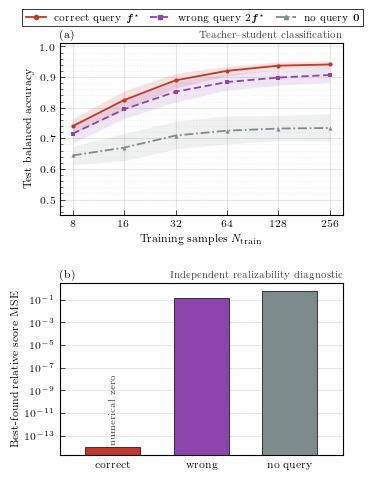

In [10]:
def panel_title(axis, letter, description):
    """Bold panel letter on the left, description on the right."""
    axis.set_title(letter, loc="left", pad=4, fontweight="bold")
    axis.set_title(description, loc="right", pad=4, fontsize=7.0, color="0.25")


def finish_axis(axis, x_minor=True, y_minor=True, grid_axis="both"):
    """Gridlines, minor ticks and spines, applied identically to every panel."""
    axis.set_axisbelow(True)
    axis.minorticks_on()
    if not x_minor:
        axis.xaxis.set_minor_locator(mticker.NullLocator())
    if not y_minor:
        axis.yaxis.set_minor_locator(mticker.NullLocator())
    axis.tick_params(which="both", top=False, right=False)
    axis.grid(True, which="major", axis=grid_axis, linestyle="-", alpha=0.30)
    axis.grid(True, which="minor", axis=grid_axis, linestyle=":", alpha=0.15)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)


fig, axes = plt.subplots(2, 1, figsize=(3.45, 4.90))

handles = [
    Line2D(
        [],
        [],
        color=COLORS[arm],
        ls=STYLE[arm],
        marker=MARKER[arm],
        ms=3.0,
        label=LABELS[arm],
    )
    for arm in ARMS
]
legend = fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.55, 0.997),
    ncol=3,
    frameon=True,
    framealpha=0.9,
    edgecolor="black",
    fancybox=False,
)
legend.get_frame().set_linewidth(0.6)


# (a) Query-aligned teacher-student classification
axis = axes[0]
sample_counts = np.asarray(SUMMARY["n"])
for arm_index, arm in enumerate(SUMMARY["arms"]):
    mean = np.asarray(SUMMARY["estimate"][arm_index])
    lower = np.asarray(SUMMARY["lower"][arm_index])
    upper = np.asarray(SUMMARY["upper"][arm_index])
    axis.plot(
        sample_counts,
        mean,
        color=COLORS[arm],
        ls=STYLE[arm],
        marker=MARKER[arm],
        ms=3.0,
        mew=0.0,
    )
    axis.fill_between(
        sample_counts,
        lower,
        upper,
        color=COLORS[arm],
        alpha=BAND_ALPHA[arm],
        linewidth=0,
    )

axis.set_xscale("log", base=2)
axis.set_xticks(SUMMARY["n"])
axis.set_xticklabels([str(n) for n in SUMMARY["n"]])
axis.set_ylim(0.45, 1.01)
axis.set_xlabel(r"Training samples $N_{\rm train}$")
axis.set_ylabel("Test balanced accuracy")
panel_title(axis, "(a)", f"Teacher{DASH}student classification")
# Fixed decade ticks on the log-2 axis; minor log ticks would clutter it.
finish_axis(axis, x_minor=False)


# (b) Independent realizability diagnostic
score_teacher_level = (
    SCORE_RESULTS.groupby("arm", as_index=False)["relative_mse"]
    .median()
    .set_index("arm")
    .reindex(list(ARMS))
)
display_floor = 1e-14
raw_values = score_teacher_level["relative_mse"].to_numpy()
display_values = np.maximum(raw_values, display_floor)

axis = axes[1]
positions = np.arange(len(ARMS))
axis.bar(
    positions,
    display_values,
    color=[COLORS[arm] for arm in ARMS],
    width=0.62,
    edgecolor="black",
    linewidth=0.5,
    zorder=2,
)
axis.set_yscale("log")
axis.set_xticks(positions)
axis.set_xticklabels(["correct", "wrong", "no query"])
axis.set_xlim(-0.6, len(ARMS) - 0.4)
axis.set_ylabel("Best-found relative score MSE")
panel_title(axis, "(b)", "Independent realizability diagnostic")
# Horizontal rules only: vertical gridlines behind bars read as clutter.
finish_axis(axis, x_minor=False, grid_axis="y")

for position, value in zip(positions, raw_values):
    if value < display_floor:
        axis.text(
            position,
            display_floor * 1.4,
            "numerical zero",
            ha="center",
            va="bottom",
            fontsize=6.6,
            rotation=90,
            color="0.25",
            zorder=3,
        )

fig.subplots_adjust(
    left=0.165,
    right=0.985,
    bottom=0.078,
    top=0.918,
    hspace=0.40,
)

for suffix in (".pdf", ".png"):
    fig.savefig(
        FIGURES_DIR / f"{FIGURE_STEM}{suffix}",
        dpi=600,
        pad_inches=0.05,
        bbox_inches="tight",
    )
plt.show()

## Supplementary figure: decision boundaries

For teacher 0 and fold 0, the students are refit using exactly the data, seeds
and optimization budget of the Stage B run, so the balanced accuracies shown
reproduce the corresponding rows of the cached classification results (printed
for comparison). (a) Teacher score $v_T$ and its zero level set.
(b–d) Learned boundary against the teacher boundary for the correct query at
$N_{\rm train}=32$ and $256$, and for the no-query arm at $N_{\rm train}=256$,
whose score factorizes as $g(x_0)\,h(x_1)$ so that its boundary consists of
straight lines only.

teacher 0, fold 0: 8.7% of test inputs have |v_T| < 0.05
  correct N= 32: balanced accuracy 0.821 (Stage B: 0.821), error rate 17.5%, 22% of errors have |v_T| < 0.05
  correct N=256: balanced accuracy 0.936 (Stage B: 0.936), error rate 6.1%, 56% of errors have |v_T| < 0.05
  none    N=256: balanced accuracy 0.754 (Stage B: 0.754), error rate 23.4%, 18% of errors have |v_T| < 0.05


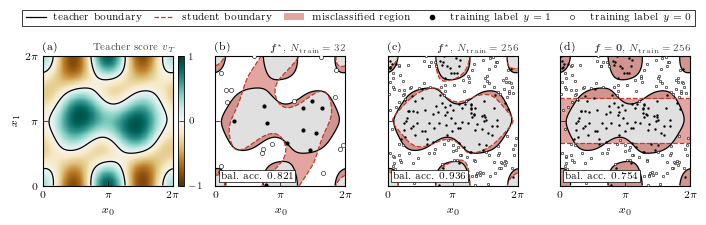

In [11]:
BOUNDARY_TEACHER = 0
BOUNDARY_FOLD = 0
BOUNDARY_CASES = (("correct", 32), ("correct", 256), ("none", 256))
ERROR_COLOR = COLORS["correct"]
GRID_POINTS = 241
NEAR_BOUNDARY = 0.05

teacher = TEACHERS[BOUNDARY_TEACHER]
theta_teacher = teacher["full_parameters"]


def teacher_labels(x):
    return (np.asarray(forward(theta_teacher, x, F_STAR, CFG)) > 0).astype(float)


# The same test set and training pool as run_classification_experiment.
x_test = rng_from(BASE_SEED, 400, BOUNDARY_TEACHER).uniform(
    0, 2 * np.pi, (P["n_test"], CFG.n_qubits)
)
y_test = teacher_labels(x_test)
x_pool = rng_from(BASE_SEED, 401, BOUNDARY_TEACHER, BOUNDARY_FOLD).uniform(
    0, 2 * np.pi, (max(P["n_grid"]), CFG.n_qubits)
)
y_pool = teacher_labels(x_pool)

axis_values = np.linspace(0.0, 2 * np.pi, GRID_POINTS)
grid_x0, grid_x1 = np.meshgrid(axis_values, axis_values, indexing="xy")
grid_points = np.stack([grid_x0.ravel(), grid_x1.ravel()], axis=1)
teacher_grid = np.asarray(
    forward(theta_teacher, grid_points, F_STAR, CFG)
).reshape(grid_x0.shape)
teacher_test_score = np.asarray(forward(theta_teacher, x_test, F_STAR, CFG))

students = {}
for arm, n in BOUNDARY_CASES:
    f_arm = ARMS[arm]
    fit = fit_classifier(
        CFG,
        f_arm,
        x_pool[:n],
        y_pool[:n],
        x_test,
        y_test,
        seed=1_000_000 * BOUNDARY_TEACHER + 10_000 * BOUNDARY_FOLD + n,
    )
    theta_student = CFG.expand(fit["free_parameters"])
    student_grid = np.asarray(
        forward(theta_student, grid_points, f_arm, CFG)
    ).reshape(grid_x0.shape)
    wrong = (
        np.asarray(forward(theta_student, x_test, f_arm, CFG)) > 0
    ) != (y_test > 0)
    students[arm, n] = {
        "grid": student_grid,
        "accuracy": fit["test_balanced_accuracy"],
        "error_rate": float(np.mean(wrong)),
        # Share of misclassified test points that lie close to the teacher
        # boundary, against the share of all test points that do.
        "errors_near": float(np.mean(np.abs(teacher_test_score[wrong]) < NEAR_BOUNDARY)),
    }

boundary_mass = float(np.mean(np.abs(teacher_test_score) < NEAR_BOUNDARY))
print(
    f"teacher {BOUNDARY_TEACHER}, fold {BOUNDARY_FOLD}: "
    f"{100 * boundary_mass:.1f}% of test inputs have |v_T| < {NEAR_BOUNDARY}"
)
for (arm, n), student in students.items():
    cached_accuracy = CLASSIFICATION_RESULTS.query(
        "teacher == @BOUNDARY_TEACHER and fold == @BOUNDARY_FOLD "
        "and arm == @arm and n == @n"
    )[PRIMARY_METRIC].item()
    print(
        f"  {arm:7s} N={n:3d}: balanced accuracy {student['accuracy']:.3f} "
        f"(Stage B: {cached_accuracy:.3f}), "
        f"error rate {100 * student['error_rate']:.1f}%, "
        f"{100 * student['errors_near']:.0f}% of errors have |v_T| < {NEAR_BOUNDARY}"
    )


def angle_axis(axis, show_y=True):
    ticks = [0.0, np.pi, 2 * np.pi]
    labels = [r"$0$", r"$\pi$", r"$2\pi$"]
    axis.set_xlim(0.0, 2 * np.pi)
    axis.set_ylim(0.0, 2 * np.pi)
    axis.set_aspect("equal")
    axis.set_xticks(ticks)
    axis.set_xticklabels(labels)
    axis.set_yticks(ticks)
    axis.set_yticklabels(labels if show_y else [])
    axis.set_xlabel(r"$x_0$")
    if show_y:
        axis.set_ylabel(r"$x_1$")
    axis.tick_params(which="both", top=False, right=False)
    for spine in axis.spines.values():
        spine.set_linewidth(0.8)


fig, axes = plt.subplots(1, 1 + len(BOUNDARY_CASES), figsize=(7.08, 2.25))
colorbar_axes = [
    make_axes_locatable(axis).append_axes("right", size="5%", pad=0.05)
    for axis in axes
]

# (a) Continuous teacher score and its zero level set
axis = axes[0]
image = axis.pcolormesh(
    grid_x0, grid_x1, teacher_grid,
    cmap="BrBG", vmin=-1.0, vmax=1.0, shading="auto", rasterized=True,
)
axis.contour(grid_x0, grid_x1, teacher_grid, levels=[0.0], colors="black", linewidths=0.9)
angle_axis(axis)
panel_title(axis, "(a)", r"Teacher score $v_T$")
colorbar = fig.colorbar(image, cax=colorbar_axes[0], ticks=[-1, 0, 1])
colorbar.outline.set_linewidth(0.6)
colorbar.ax.tick_params(labelsize=7)

# (b-d) Learned boundary against the teacher boundary
QUERY_TEXT = {
    "correct": r"$\boldsymbol{f}^\star$",
    "wrong": r"$2\boldsymbol{f}^\star$",
    "none": r"$\boldsymbol{f}=\boldsymbol{0}$",
}
teacher_positive = teacher_grid > 0
for axis, cax, letter, (arm, n) in zip(
    axes[1:], colorbar_axes[1:], ("(b)", "(c)", "(d)"), BOUNDARY_CASES
):
    student = students[arm, n]
    disagreement = (student["grid"] > 0) != teacher_positive
    # Teacher classes in two light greys, disagreement on top in the arm colour.
    axis.pcolormesh(
        grid_x0, grid_x1, teacher_positive.astype(float),
        cmap=mpl.colors.ListedColormap(["white", "0.88"]),
        vmin=0, vmax=1, shading="auto", rasterized=True,
    )
    axis.pcolormesh(
        grid_x0, grid_x1, np.ma.masked_where(~disagreement, disagreement),
        cmap=mpl.colors.ListedColormap([ERROR_COLOR]),
        alpha=0.45, shading="auto", rasterized=True,
    )
    axis.contour(grid_x0, grid_x1, teacher_grid, levels=[0.0], colors="black", linewidths=0.9)
    axis.contour(
        grid_x0, grid_x1, student["grid"], levels=[0.0],
        colors=ERROR_COLOR, linewidths=0.9, linestyles="--",
    )
    positive = y_pool[:n] > 0
    marker_size = 9 if n <= 64 else 3
    axis.scatter(
        x_pool[:n][positive, 0], x_pool[:n][positive, 1],
        s=marker_size, c="black", lw=0, zorder=3,
    )
    axis.scatter(
        x_pool[:n][~positive, 0], x_pool[:n][~positive, 1],
        s=marker_size, facecolors="white", edgecolors="black", lw=0.4, zorder=3,
    )
    axis.text(
        0.04, 0.04,
        rf"bal.\ acc.\ ${student['accuracy']:.3f}$" if USE_TEX
        else f"bal. acc. {student['accuracy']:.3f}",
        transform=axis.transAxes, ha="left", va="bottom", fontsize=6.8,
        bbox=dict(facecolor="white", edgecolor="black", linewidth=0.5, pad=1.5),
        zorder=4,
    )
    angle_axis(axis, show_y=False)
    panel_title(axis, letter, QUERY_TEXT[arm] + rf", $N_{{\rm train}}={n}$")
    cax.set_visible(False)

legend_handles = [
    Line2D([], [], color="black", lw=0.9, label="teacher boundary"),
    Line2D([], [], color=ERROR_COLOR, lw=0.9, ls="--", label="student boundary"),
    Patch(facecolor=ERROR_COLOR, alpha=0.45, label="misclassified region"),
    Line2D([], [], ls="", marker="o", ms=3.0, color="black", label=r"training label $y=1$"),
    Line2D([], [], ls="", marker="o", ms=3.0, mfc="white", mec="black", mew=0.4, label=r"training label $y=0$"),
]
legend = fig.legend(
    handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
    ncol=5, frameon=True, framealpha=0.9, edgecolor="black", fancybox=False,
)
legend.get_frame().set_linewidth(0.6)
fig.subplots_adjust(left=0.055, right=0.985, bottom=0.17, top=0.80, wspace=0.22)

for suffix in (".pdf", ".png"):
    fig.savefig(
        FIGURES_DIR / f"{FIGURE_STEM}_decision_boundary{suffix}",
        pad_inches=0.05,
        bbox_inches="tight",
        dpi=400,
    )
plt.show()